In [1]:
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt

# Carregamos a base em formato de tabela.
iris = load_iris(as_frame=True)
df_iris = iris.frame.copy()

# Trocamos os códigos das espécies pelos nomes.
nomes_especies = dict(enumerate(iris.target_names))
df_iris["species"] = df_iris["target"].map(nomes_especies)
df_iris = df_iris.drop(columns="target")

especies = list(iris.target_names)
cores = ["#246C9C", "#D17A20", "#34805A"]


## 1. Como as três espécies estão representadas na base?

Vamos contar as flores de cada espécie. O gráfico de barras permite comparar essas quantidades. Em plt.bar, o primeiro argumento define as categorias e o segundo fornece a altura de cada barra.

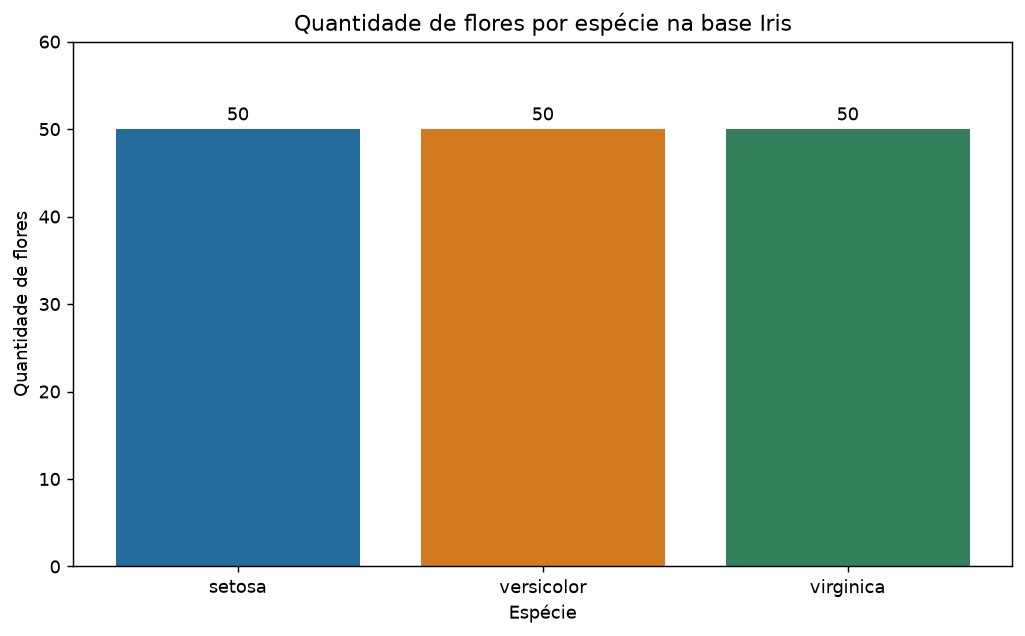

In [2]:
# value_counts conta quantas flores pertencem a cada espécie.
contagem = df_iris["species"].value_counts().reindex(especies)

plt.figure(figsize=(8, 5))
plt.bar(contagem.index, contagem.values, color=cores)

# Escrevemos a quantidade acima de cada barra.
for especie, quantidade in contagem.items():
    plt.text(especie, quantidade + 1, str(quantidade), ha="center")

plt.title("Quantidade de flores por espécie na base Iris")
plt.xlabel("Espécie")
plt.ylabel("Quantidade de flores")
plt.ylim(0, 60)
plt.tight_layout()
plt.show()


O gráfico mostra 50 flores setosa, 50 versicolor e 50 virginica. As barras têm a mesma altura porque cada espécie corresponde a um terço das 150 observações. Portanto, as espécies estão igualmente representadas nesta base. Essa proporção descreve a amostra usada na atividade e não informa a frequência das espécies na natureza.

## 2. Quais características das pétalas ajudam a diferenciar as espécies?

Vamos representar o comprimento e a largura das pétalas juntos. Cada ponto será uma flor e sua cor indicará a espécie. A posição horizontal mostra o comprimento e a posição vertical mostra a largura. Procuramos grupos de cores separados e regiões onde eles se misturam.

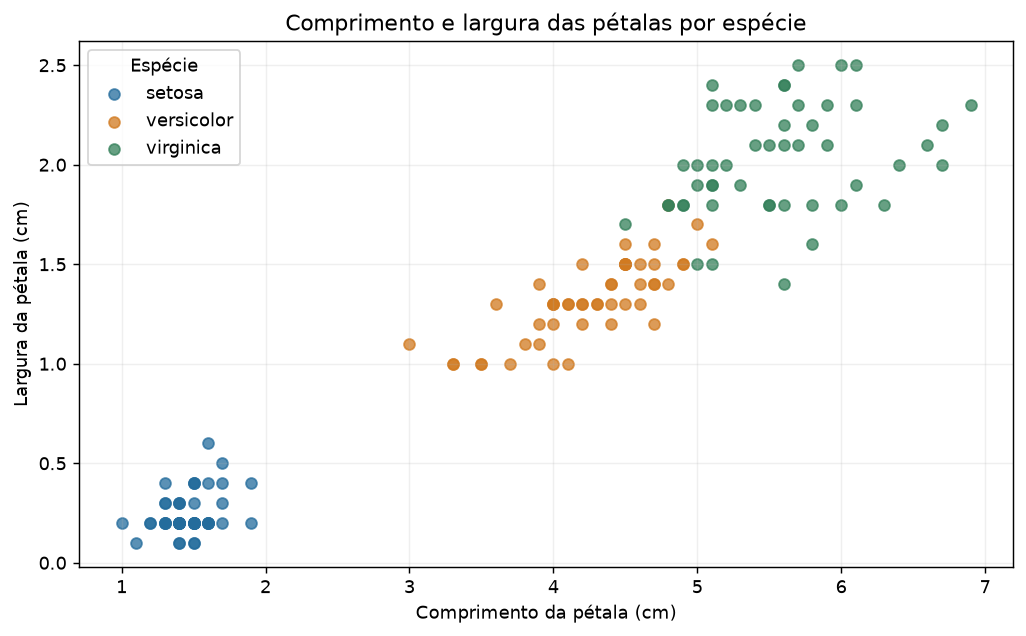

In [3]:
plt.figure(figsize=(8, 5))

for especie, cor in zip(especies, cores):
    # O filtro seleciona somente as flores da espécie atual.
    grupo = df_iris[df_iris["species"] == especie]
    plt.scatter(
        grupo["petal length (cm)"],
        grupo["petal width (cm)"],
        label=especie,
        color=cor,
        alpha=0.75
    )

plt.title("Comprimento e largura das pétalas por espécie")
plt.xlabel("Comprimento da pétala (cm)")
plt.ylabel("Largura da pétala (cm)")
plt.legend(title="Espécie")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


As flores setosa formam um grupo separado, com pétalas mais curtas e estreitas. As versicolor ocupam principalmente a região intermediária, enquanto as virginica apresentam, em geral, pétalas mais compridas e largas. As duas características ajudam a diferenciar as espécies, e sua leitura conjunta evidencia a separação da setosa e a proximidade entre versicolor e virginica. Algumas flores dessas duas últimas espécies têm medidas semelhantes. O gráfico sustenta o uso das duas medidas em conjunto, mas uma escolha rigorosa da melhor medida isolada exigiria definir e avaliar um critério de separação.

## 3. Existe relação entre o comprimento da sépala e o comprimento da pétala?

Vamos usar um gráfico de dispersão. Cada ponto reúne as duas medidas de uma mesma flor. A cor permite observar a tendência dentro de cada espécie e comparar os grupos.

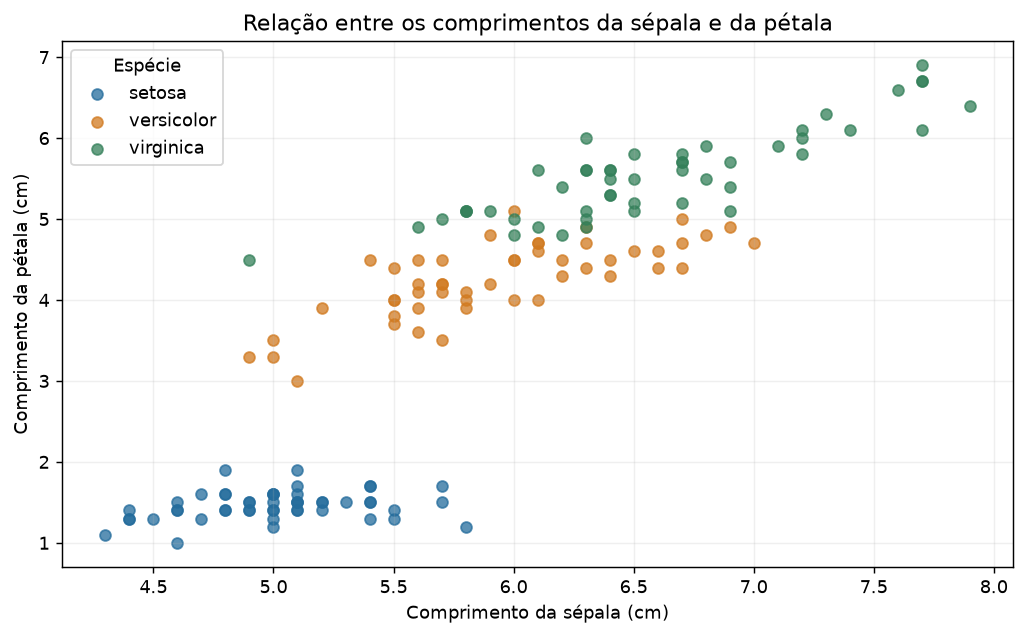

In [4]:
plt.figure(figsize=(8, 5))

for especie, cor in zip(especies, cores):
    grupo = df_iris[df_iris["species"] == especie]
    plt.scatter(
        grupo["sepal length (cm)"],
        grupo["petal length (cm)"],
        label=especie,
        color=cor,
        alpha=0.75
    )

plt.title("Relação entre os comprimentos da sépala e da pétala")
plt.xlabel("Comprimento da sépala (cm)")
plt.ylabel("Comprimento da pétala (cm)")
plt.legend(title="Espécie")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


No conjunto das flores, os pontos tendem a subir da esquerda para a direita, indicando que sépalas mais compridas costumam acompanhar pétalas mais compridas. Dentro das espécies, essa tendência é mais evidente em versicolor e virginica. Na setosa, o comprimento das pétalas varia pouco e a associação visual é mais fraca. Assim, a tendência do conjunto reúne diferenças entre espécies e variações dentro de cada espécie. A associação observada não demonstra que o comprimento de uma parte cause o comprimento da outra.

## Conclusão

A base apresenta quantidades iguais das três espécies. As medidas das pétalas destacam a setosa e ajudam a comparar versicolor e virginica, cujos valores apresentam alguma sobreposição. Os comprimentos de sépalas e pétalas tendem a variar juntos, com diferenças entre espécies. A análise descreve uma amostra de 150 flores e tem como limitação a impossibilidade de generalizar suas proporções para a natureza.